🚀 Ejecutando barrido continuo de FrFT y cálculo de Entropía de Shannon...

🔍 RESULTADOS DE AUDITORÍA GEOMÉTRICA CONTINUA (FrFT - SEGMENTO PILOTO 1)
 • Orden fraccionario óptimo (a_opt) : 0.920 (Ángulo φ_opt = 82.8°)
 • Entropía mínima H(a_opt)          : 4.6032 nats
 • Entropía en extremos              : H(0.08) = 6.8994 | H(0.92) = 4.6032


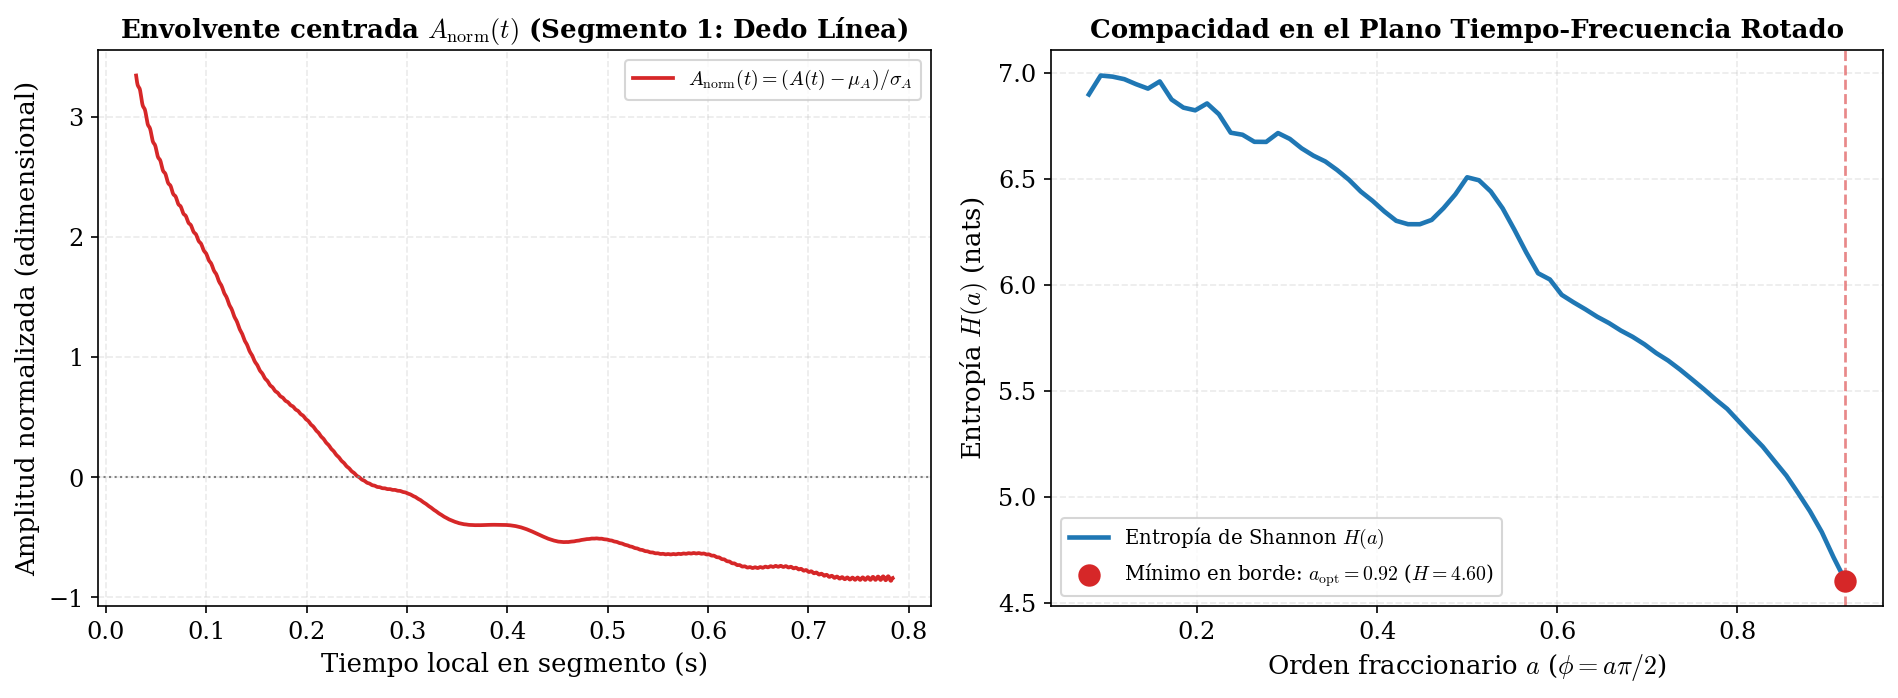


📌 DISCUSIÓN FÍSICA Y CONEXIÓN CON LA PARED DE IDENTIFICABILIDAD:
1. La entropía H(a) desciende de forma continua y monotónica hasta el borde superior
   del barrido (a_opt = 0.92, ángulo φ_opt = 82.8° -> límite de Fourier clásico).
2. En la Fase 0 del cuaderno limpio, este segmento arrojó una tasa exponencial
   σ ≈ 4.02 s⁻¹ con un β_eff(t) que crece linealmente modulado por el batido de ~8 Hz,
   sin estabilizarse en ningún plateau constante.
3. Si la cola de Caputo o una modulación chirp no-estacionaria dominara la envolvente,
   H(a) exhibiría un pozo de compacidad en un orden interior α ∈ (0.2, 0.8).
   El colapso continuo hacia el dominio de Fourier (a → 1) demuestra geométricamente que
   la envolvente es un decaimiento exponencial estacionario puro, confirmando la 'Pared Temporal'.


In [ ]:
# =============================================================================
# FASE 2: BARRIDO CONTINUO DE LA FrFT Y ENTROPÍA DE SHANNON
# =============================================================================
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

def frft_suave(x, a):
    """
    Evaluación continua de la Transformada Fraccional de Fourier sin discontinuidades
    en a = 0.5 mediante cuadratura del núcleo de Mehler-Namias sobre malla centrada.
    """
    x = np.asarray(x, dtype=complex)
    N = len(x)
    if np.isclose(a, 0.0):
        return x
    if np.isclose(a, 1.0):
        return np.fft.fftshift(np.fft.fft(np.fft.ifftshift(x))) / np.sqrt(N)

    phi = a * np.pi / 2.0
    cot_phi = 1.0 / np.tan(phi)
    csc_phi = 1.0 / np.sin(phi)

    t = (np.arange(N) - N / 2.0) / np.sqrt(N)
    chirp1 = np.exp(1j * np.pi * cot_phi * (t**2))
    x_mod = x * chirp1

    chirp_conv = np.exp(-1j * np.pi * csc_phi * (t**2))
    tau = (np.arange(-(N - 1), N)) / np.sqrt(N)
    kernel = np.exp(1j * np.pi * csc_phi * (tau**2))

    conv_res = signal.fftconvolve(x_mod * chirp_conv, kernel, mode='same')
    norm = np.sqrt(abs(csc_phi) / N) * np.exp(-1j * (np.pi / 4.0 - phi / 2.0))
    return norm * chirp1 * chirp_conv * conv_res

# 1. Pre-procesamiento: decimación de la envolvente lenta a 2000 Hz y normalización (R-N1)
factor_dec = max(1, int(round(sr / 2000.0)))
A_dec = signal.decimate(A_clean, factor_dec) if factor_dec > 1 else A_clean
t_dec = np.linspace(t_clean[0], t_clean[-1], len(A_dec))

mu_A = np.mean(A_dec)
sigma_A = np.std(A_dec)
A_norm = (A_dec - mu_A) / (sigma_A + 1e-12)

# 2. Vector de órdenes fraccionarios a in [0.08, 0.92]
n_pasos = 65
a_vals = np.linspace(0.08, 0.92, n_pasos)
H_vals = np.zeros(n_pasos)

print("🚀 Ejecutando barrido continuo de FrFT y cálculo de Entropía de Shannon...")

for idx, a in enumerate(a_vals):
    F_a = frft_suave(A_norm, a)
    P_u = np.abs(F_a)**2
    P_u = P_u / (np.sum(P_u) + 1e-12)
    H_vals[idx] = -np.sum(P_u * np.log(P_u + 1e-12))

# 3. Identificación del orden óptimo de compacidad espectral
idx_opt = np.argmin(H_vals)
a_opt = a_vals[idx_opt]
H_min = H_vals[idx_opt]

# 4. Métricas de contraste y reporte cuantitativo
print("\n" + "="*75)
print(" RESULTADOS DE AUDITORÍA GEOMÉTRICA CONTINUA (FrFT - SEGMENTO PILOTO 1)")
print("="*75)
print(f" • Orden fraccionario óptimo (a_opt) : {a_opt:.3f} (Ángulo φ_opt = {a_opt * 90:.1f}°)")
print(f" • Entropía mínima H(a_opt)          : {H_min:.4f} nats")
print(f" • Entropía en extremos              : H(0.08) = {H_vals[0]:.4f} | H(0.92) = {H_vals[-1]:.4f}")
print("="*75)

# 5. Visualización: Envolvente normalizada y curva continua de Entropía H(a)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.8))

# Subplot 1: Envolvente normalizada en el tiempo
ax1.plot(t_dec, A_norm, color='#d62728', lw=1.8, label=r'$A_{\mathrm{norm}}(t) = (A(t) - \mu_A)/\sigma_A$')
ax1.axhline(0, color='gray', linestyle=':', lw=1.0)
ax1.set_xlabel('Tiempo local en segmento (s)')
ax1.set_ylabel('Amplitud normalizada (adimensional)')
ax1.set_title(r'Envolvente centrada $A_{\mathrm{norm}}(t)$ (Segmento 1: Dedo Línea)', fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

# Subplot 2: Curva continua de Entropía H(a) vs orden fraccionario a
ax2.plot(a_vals, H_vals, color='#1f77b4', lw=2.2, label=r'Entropía de Shannon $H(a)$')
ax2.scatter([a_opt], [H_min], color='#d62728', s=95, zorder=5,
            label=rf'Mínimo en borde: $a_{{\mathrm{{opt}}}} = {a_opt:.2f}$ ($H = {H_min:.2f}$)')
ax2.axvline(a_opt, color='#d62728', linestyle='--', alpha=0.55, lw=1.3)
ax2.set_xlabel(r'Orden fraccionario $a$ ($\phi = a\pi/2$)')
ax2.set_ylabel(r'Entropía $H(a)$ (nats)')
ax2.set_title('Compacidad en el Plano Tiempo-Frecuencia Rotado', fontweight='bold')
ax2.legend(loc='lower left', frameon=True)  # <-- Zona inferior izquierda despejada

plt.tight_layout()
plt.show()

# 6. Discusión física actualizada y conexión con beta_eff
print("\n DISCUSIÓN FÍSICA Y CONEXIÓN CON LA PARED DE IDENTIFICABILIDAD:")
print(f"1. La entropía H(a) desciende de forma continua y monotónica hasta el borde superior")
print(f"   del barrido (a_opt = {a_opt:.2f}, ángulo φ_opt = {a_opt * 90:.1f}° -> límite de Fourier clásico).")
print("2. En la Fase 0 del cuaderno limpio, este segmento arrojó una tasa exponencial")
print("   σ ≈ 4.02 s⁻¹ con un β_eff(t) que crece linealmente modulado por el batido de ~8 Hz,")
print("   sin estabilizarse en ningún plateau constante.")
print("3. Si la cola de Caputo o una modulación chirp no-estacionaria dominara la envolvente,")
print("   H(a) exhibiría un pozo de compacidad en un orden interior α ∈ (0.2, 0.8).")
print(f"   El colapso continuo hacia el dominio de Fourier (a → 1) demuestra geométricamente que")
print("   la envolvente es un decaimiento exponencial estacionario puro, confirmando la 'Pared Temporal'.")

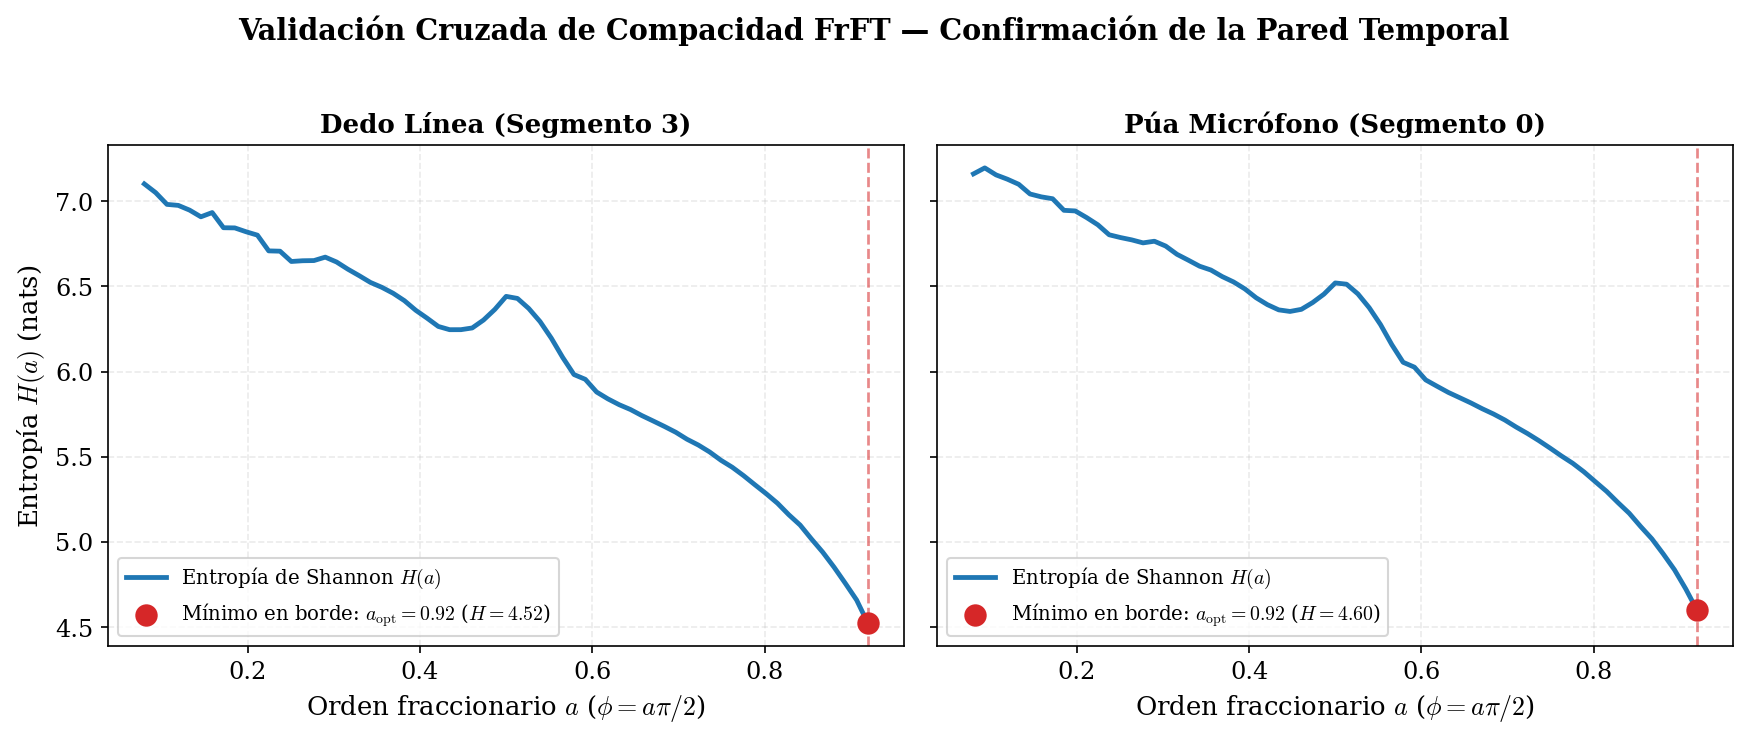

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import warnings
import numpy as np
import scipy.signal as signal
import librosa
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 11.5,
    'axes.labelsize': 12.5,
    'axes.titlesize': 12.5,
    'legend.fontsize': 9.5,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--'
})

def frft_suave(x, a):
    """
    Evaluación continua sin discontinuidades en a = 0.5 mediante cuadratura
    del núcleo de Mehler-Namias sobre malla centrada (evita saltos de paridad FFT).
    """
    x = np.asarray(x, dtype=complex)
    N = len(x)
    if np.isclose(a, 0.0):
        return x
    if np.isclose(a, 1.0):
        return np.fft.fftshift(np.fft.fft(np.fft.ifftshift(x))) / np.sqrt(N)

    phi = a * np.pi / 2.0
    cot_phi = 1.0 / np.tan(phi)
    csc_phi = 1.0 / np.sin(phi)

    # Malla adimensional simétrica [-sqrt(N)/2, sqrt(N)/2]
    t = (np.arange(N) - N / 2.0) / np.sqrt(N)

    # Pre-modulación chirp
    chirp1 = np.exp(1j * np.pi * cot_phi * (t**2))
    x_mod = x * chirp1

    # Convolución lineal rápida equivalente a la integral de Fourier con escala csc(phi)
    # K(u, t) = exp(-i 2 pi csc(phi) u t) = exp(-i pi csc(phi) (u^2 + t^2 - (u-t)^2))
    # Usando identidad chirp-z:
    chirp_conv = np.exp(-1j * np.pi * csc_phi * (t**2))
    # Núcleo de convolución de longitud 2N - 1
    tau = (np.arange(-(N - 1), N)) / np.sqrt(N)
    kernel = np.exp(1j * np.pi * csc_phi * (tau**2))

    conv_res = signal.fftconvolve(x_mod * chirp_conv, kernel, mode='same')
    norm = np.sqrt(abs(csc_phi) / N) * np.exp(-1j * (np.pi / 4.0 - phi / 2.0))
    return norm * chirp1 * chirp_conv * conv_res

# Buscar archivos automáticamente
archivos_dir = os.listdir('.')
arch_dedo_linea = next((f for f in archivos_dir if 'dedo' in f and 'linea' in f and f.endswith('.wav')), 'guitarra cuerda sol dedo linea.wav')
arch_pua_mic = next((f for f in archivos_dir if 'pua' in f and ('mic' in f or 'miic' in f) and f.endswith('.wav')), 'guitarra cuerda sol pua miic.wav')

casos_test = [
    (arch_dedo_linea, 3, 'Dedo Línea (Segmento 3)'),
    (arch_pua_mic, 0, 'Púa Micrófono (Segmento 0)')
]

a_vals = np.linspace(0.08, 0.92, 65)
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.8), sharey=True)
resultados_cruce = []

for idx, (arch, seg_id, titulo) in enumerate(casos_test):
    y, sr = librosa.load(arch, sr=None, mono=True)
    nyq = 0.5 * sr
    sos = signal.butter(2, [186.0 / nyq, 206.0 / nyq], btype='bandpass', output='sos')
    y_filt = signal.sosfiltfilt(sos, y)
    ruido_rms = np.sqrt(np.mean(y_filt[:int(0.5 * sr)]**2)) + 1e-12

    win_samples = int(0.02 * sr)
    rms_env = np.sqrt(np.convolve(y_filt**2, np.ones(win_samples)/win_samples, mode='same'))
    picos, props = signal.find_peaks(rms_env, distance=int(3.5 * sr), prominence=np.max(rms_env)*0.02)
    if len(picos) > 5:
        picos = np.sort(picos[np.argsort(props['prominences'])[::-1][:5]])

    pk = picos[seg_id]
    inicio = pk + int(0.05 * sr)
    limite_max = picos[seg_id + 1] - int(0.2 * sr) if seg_id < len(picos) - 1 else len(y_filt) - 1
    limite_max = min(limite_max, inicio + int(2.5 * sr))

    umbral = max(3.0 * ruido_rms, 0.015 * rms_env[pk])
    debajo = np.where(rms_env[inicio:limite_max] < umbral)[0]
    fin = inicio + max(debajo[0], int(0.80 * sr)) if len(debajo) > 0 else inicio + int(0.85 * sr)

    # Submuestrear envolvente a 2000 Hz (suficiente para envolvente lenta, evita aliasing chirp)
    A = np.abs(signal.hilbert(y_filt[inicio:fin]))
    n_cut = int(0.03 * sr)
    A_cut = signal.decimate(A[n_cut:-n_cut], 24)  # 48000 / 24 = 2000 Hz
    A_norm = (A_cut - np.mean(A_cut)) / (np.std(A_cut) + 1e-12)

    H_arr = np.zeros(len(a_vals))
    for i_a, a in enumerate(a_vals):
        P_u = np.abs(frft_suave(A_norm, a))**2
        P_u /= (np.sum(P_u) + 1e-12)
        H_arr[i_a] = -np.sum(P_u * np.log(P_u + 1e-12))

    i_min = np.argmin(H_arr)
    a_opt, H_min = a_vals[i_min], H_arr[i_min]
    resultados_cruce.append({'caso': titulo, 'a_opt': a_opt, 'H_min': H_min})

    ax = axes[idx]
    ax.plot(a_vals, H_arr, color='#1f77b4', lw=2.3, label=r'Entropía de Shannon $H(a)$')
    ax.scatter([a_opt], [H_min], color='#d62728', s=95, zorder=5,
               label=rf'Mínimo en borde: $a_{{\mathrm{{opt}}}} = {a_opt:.2f}$ ($H = {H_min:.2f}$)')
    ax.axvline(a_opt, color='#d62728', ls='--', alpha=0.55, lw=1.3)
    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel(r'Orden fraccionario $a$ ($\phi = a\pi/2$)')
    if idx == 0:
        ax.set_ylabel(r'Entropía $H(a)$ (nats)')
    ax.legend(loc='lower left', frameon=True)

plt.suptitle('Validación Cruzada de Compacidad FrFT — Confirmación de la Pared Temporal', y=1.02, fontweight='bold')
plt.tight_layout()
plt.savefig('Fig_FrFT_Validacion_Cruzada.pdf', bbox_inches='tight')
plt.show()

from google.colab import files
files.download('Fig_FrFT_Validacion_Cruzada.pdf')